# Étape 2 — Partie Membre 2 : outliers, distributions et transformations

### B1. Chargement des données (sortie du membre 1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# keep_default_na=False : 'None' (examen non réalisé) reste une catégorie
# na_values=['']        : seules les cases vides (diag_1/2/3) deviennent NaN
df = pd.read_csv('data_etape2a.csv', keep_default_na=False, na_values=[''], low_memory=False)

print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])
print(df['A1Cresult'].value_counts())

(69987, 50)
diag_1      10
diag_2     293
diag_3    1224
dtype: int64
A1Cresult
None    57141
>8       6239
Norm     3741
>7       2866
Name: count, dtype: int64


In [2]:
numeriques = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
              'num_medications', 'number_outpatient', 'number_emergency',
              'number_inpatient', 'number_diagnoses']

### B2. Vérification des valeurs impossibles


In [3]:
# Valeurs min, max et médiane : y a-t-il des valeurs impossibles ?
print(df[numeriques].agg(['min', 'max', 'median']).T)
print("Valeurs négatives :", (df[numeriques] < 0).sum().sum())

                    min    max  median
time_in_hospital    1.0   14.0     3.0
num_lab_procedures  1.0  132.0    44.0
num_procedures      0.0    6.0     1.0
num_medications     1.0   81.0    14.0
number_outpatient   0.0   42.0     0.0
number_emergency    0.0   42.0     0.0
number_inpatient    0.0   12.0     0.0
number_diagnoses    1.0   16.0     8.0
Valeurs négatives : 0


#### Conclusion : aucune erreur de saisie
Aucune valeur n'est impossible : pas de valeur négative, une durée de séjour entre 1 et 14 jours (conforme aux critères de sélection du dataset), et des comptages dans des ordres de grandeur médicalement plausibles. **Aucune valeur n'est donc une erreur de saisie à supprimer.** Les valeurs extrêmes observées correspondent à des patients réels (patients lourds ou très suivis), qui sont justement les plus intéressants pour prédire la réadmission.

### B3. Mesure des outliers (règle IQR)

In [4]:
# Pourcentage d'outliers (règle IQR) et pourcentage de zéros pour chaque variable
def pct_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

outliers = pd.DataFrame({
    '% outliers (IQR)': [round(pct_outliers(df[c]), 1) for c in numeriques],
    '% de zéros': ((df[numeriques] == 0).mean() * 100).round(1).values,
}, index=numeriques)
outliers

,% outliers (IQR),% de zéros
time_in_hospital,2.0,0.0
num_lab_procedures,0.1,0.0
num_procedures,5.5,44.1
num_medications,2.7,0.0
number_outpatient,13.0,87.0
number_emergency,7.3,92.7
number_inpatient,11.7,88.3
number_diagnoses,0.3,0.0


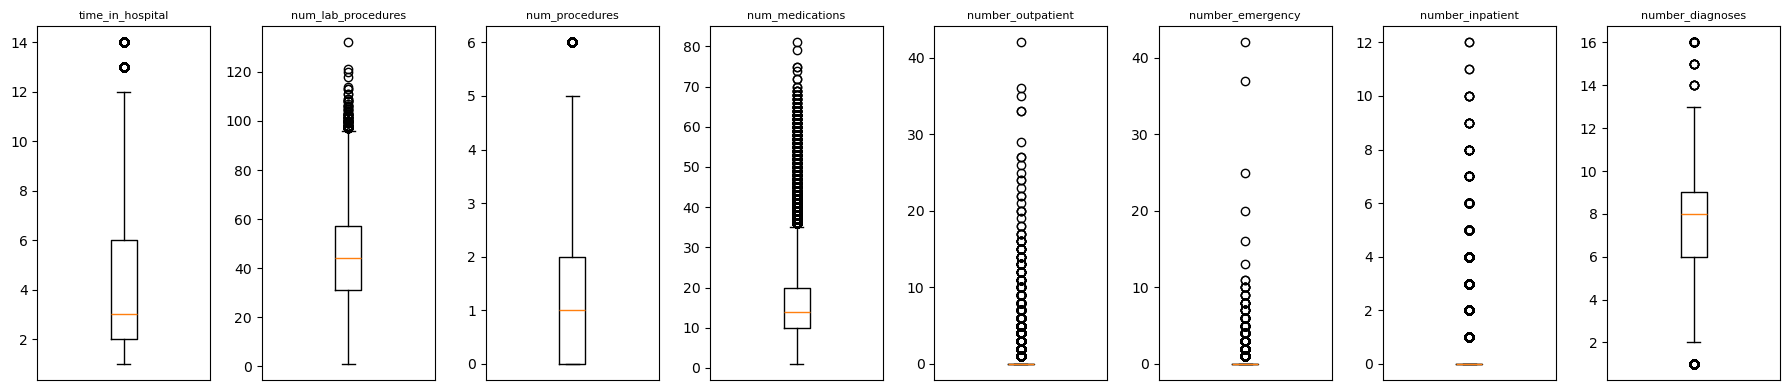

In [5]:
# Boxplots : visualiser les outliers
fig, axes = plt.subplots(1, 8, figsize=(18, 4))
for ax, col in zip(axes, numeriques):
    ax.boxplot(df[col])
    ax.set_title(col, fontsize=8)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

#### Décision : ne pas supprimer les outliers
La règle IQR signale jusqu'à 13 % d'outliers pour les variables de visites antérieures. Mais 87 à 93 % de leurs valeurs valent 0 : Q1 = Q3 = 0, donc la règle classe **toute visite** comme aberrante, ce qui n'a pas de sens médical. Pour les autres variables, les outliers sont rares (0,1 à 5,5 %) et plausibles.

Nous ne supprimons aucun outlier :
1. ce ne sont pas des erreurs (voir B2) ;
2. les supprimer ferait perdre les patients les plus lourds, qui sont les plus à risque de réadmission ;
3. cela ferait perdre jusqu'à 13 % des données.

À la place, nous **réduisons l'influence** des valeurs extrêmes par transformation (B4).

### B4. Choix de la transformation : log1p ou plafonnement

In [6]:
# Comparaison de l'asymétrie : avant, après log1p, après plafonnement au 99e percentile
comparaison = pd.DataFrame({
    'skew avant': df[numeriques].skew().round(2),
    'skew après log1p': np.log1p(df[numeriques]).skew().round(2),
    'skew après plafond 99%': df[numeriques].clip(upper=df[numeriques].quantile(0.99), axis=1).skew().round(2),
})
comparaison

,skew avant,skew après log1p,skew après plafond 99%
time_in_hospital,1.18,0.14,1.13
num_lab_procedures,-0.22,-2.17,-0.27
num_procedures,1.23,0.45,1.23
num_medications,1.43,-0.44,1.06
number_outpatient,9.70,3.15,3.55
number_emergency,21.23,4.27,4.06
number_inpatient,5.59,3.13,3.60
number_diagnoses,-0.72,-1.35,-0.78


In [7]:
# Transformation log1p uniquement là où elle réduit l'asymétrie
a_transformer = ['number_outpatient', 'number_emergency', 'number_inpatient',
                 'num_medications', 'time_in_hospital', 'num_procedures']

for col in a_transformer:
    df[col + '_log'] = np.log1p(df[col])

print(df[[c + '_log' for c in a_transformer]].skew().round(2))

number_outpatient_log    3.15
number_emergency_log     4.27
number_inpatient_log     3.13
num_medications_log     -0.44
time_in_hospital_log     0.14
num_procedures_log       0.45
dtype: float64


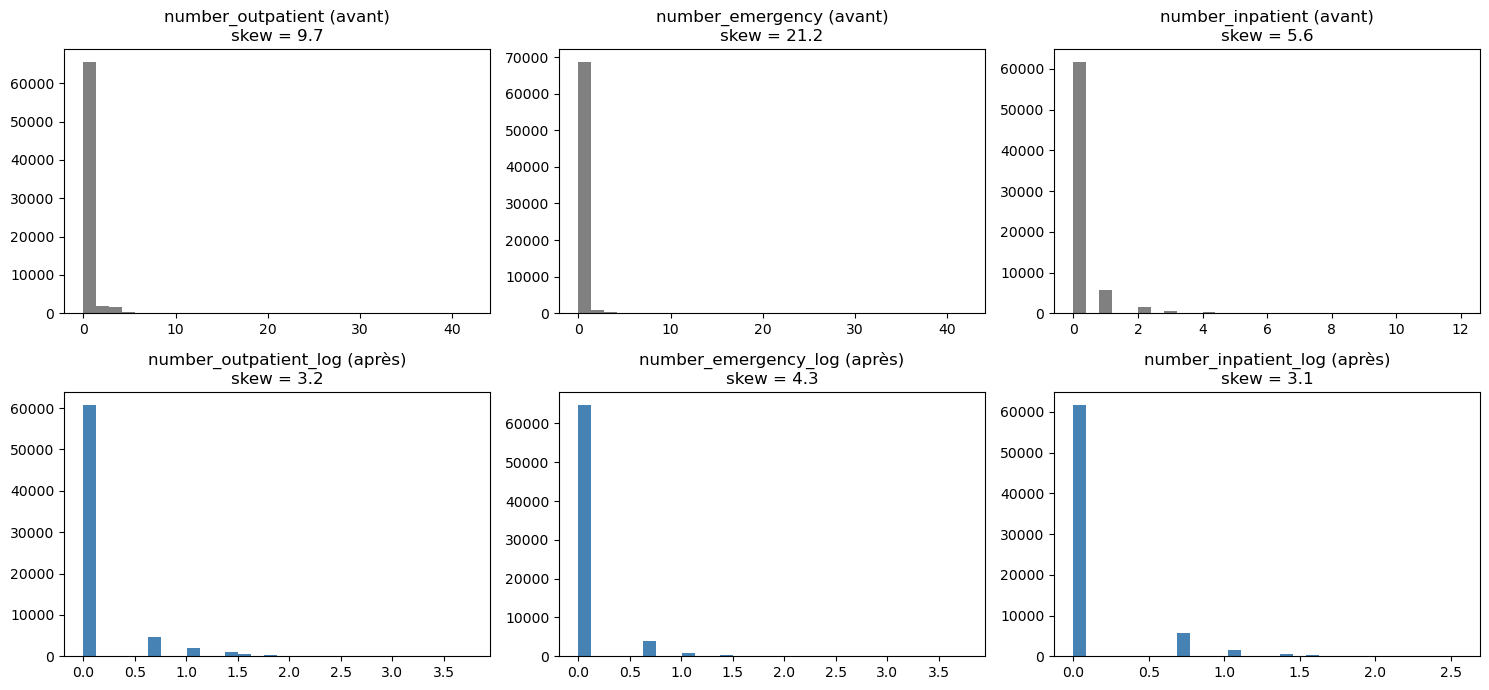

In [8]:
# Distribution avant / après log1p pour les variables de visites
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(['number_outpatient', 'number_emergency', 'number_inpatient']):
    axes[0, i].hist(df[col], bins=30, color='gray')
    axes[0, i].set_title(f"{col} (avant)\nskew = {df[col].skew():.1f}")
    axes[1, i].hist(df[col + '_log'], bins=30, color='steelblue')
    axes[1, i].set_title(f"{col}_log (après)\nskew = {df[col + '_log'].skew():.1f}")
plt.tight_layout()
plt.show()

#### Décision : transformation log1p
Nous avons comparé deux méthodes pour réduire l'asymétrie : la transformation `log1p` et le plafonnement au 99e percentile.
- Pour 5 variables sur 6 concernées, `log1p` réduit davantage l'asymétrie (par exemple de 9,70 à 3,15 pour `number_outpatient`, et de 1,43 à -0,44 pour `num_medications`).
- Pour `number_emergency`, le plafonnement donne un résultat légèrement meilleur (4,06 contre 4,27). Nous gardons tout de même `log1p` : l'écart est faible, et `log1p` **conserve l'ordre entre les patients** (un patient avec 20 passages reste au-dessus d'un patient avec 5), alors que le plafonnement les met au même niveau. Elle ne demande pas non plus de seuil arbitraire.
- `log1p` n'est **pas** appliquée à `num_lab_procedures` ni à `number_diagnoses` : elles sont déjà peu asymétriques, et le log aggraverait leur asymétrie (de -0,22 à -2,17 pour `num_lab_procedures`).
- **Limite** : pour les variables de visites, 87 à 93 % des valeurs sont nulles. Aucune transformation ne peut les rendre symétriques ; le log réduit seulement l'influence des valeurs extrêmes.

Les variables transformées sont ajoutées dans de nouvelles colonnes (`_log`) : les valeurs d'origine restent disponibles pour l'interprétation.

### B5. Valeurs suspectes

In [9]:
# Deux valeurs suspectes repérées lors de l'exploration
print("num_lab_procedures = 1 :", (df['num_lab_procedures'] == 1).sum(), "séjours")
print("   taux de réadmission :", round(df.loc[df['num_lab_procedures'] == 1, 'target'].mean() * 100, 1), "%")
print("   durée moyenne séjour:", round(df.loc[df['num_lab_procedures'] == 1, 'time_in_hospital'].mean(), 2), "jours")
print()
print("number_diagnoses = 9   :", round((df['number_diagnoses'] == 9).mean() * 100, 1), "%")
print("number_diagnoses > 9   :", (df['number_diagnoses'] > 9).sum(), "séjours")

num_lab_procedures = 1 : 2254 séjours
   taux de réadmission : 6.3 %
   durée moyenne séjour: 3.05 jours

number_diagnoses = 9   : 43.9 %
number_diagnoses > 9   : 73 séjours


#### Décision : valeurs suspectes conservées
- **`num_lab_procedures = 1`** (2 254 séjours) : valeur inhabituelle pour une hospitalisation, mais impossible à prouver fausse. La durée moyenne de ces séjours (3,05 jours) est proche de la médiane générale (3 jours) : ce ne sont pas des séjours anormaux par ailleurs. Nous les conservons, en le signalant comme limite.
- **`number_diagnoses = 9`** (43,9 % des séjours) : ce pic est très probablement dû à une limite du système de saisie (9 champs de diagnostic), les valeurs au-dessus de 9 étant très rares (73 séjours). La variable est conservée : elle reste informative, mais sa valeur maximale doit être interprétée comme « 9 ou plus ».

### B6. Choix du scaling

In [10]:
# Pourquoi RobustScaler ne convient pas : l'écart interquartile (IQR) des variables de visites vaut 0
cols_log = ['number_outpatient_log', 'number_emergency_log', 'number_inpatient_log']
q1 = df[cols_log].quantile(0.25)
q3 = df[cols_log].quantile(0.75)
print("IQR (Q3 - Q1) :")
print(q3 - q1)

IQR (Q3 - Q1) :
number_outpatient_log    0.0
number_emergency_log     0.0
number_inpatient_log     0.0
dtype: float64


#### Décision : StandardScaler (appliqué dans les modèles, pas dans ce fichier)
Les algorithmes basés sur des distances (K-Means, KNN) et la régression logistique sont sensibles aux différences d'échelle : sans mise à l'échelle, `num_lab_procedures` (jusqu'à 132) dominerait `number_inpatient_log` (jusqu'à 2,6). Nous retenons **StandardScaler** :
- **MinMaxScaler** est écarté car trop sensible aux valeurs maximales : un seul patient extrême écraserait tous les autres près de 0 ;
- **RobustScaler** est écarté car l'écart interquartile des variables de visites vaut 0 (vérifié ci-dessus), ce qui le rend inopérant.

**Le scaling n'est pas appliqué dans ce fichier.** Pour éviter toute fuite de données, il doit être ajusté uniquement sur l'ensemble d'entraînement, à l'intérieur du pipeline de classification (membre 5). Pour le clustering (membre 4), qui n'a pas d'ensemble de test, il peut être ajusté sur l'ensemble des données.

### B7. Vérification finale et sauvegarde

In [11]:
# Vérifications avant de transmettre le fichier
cols_log = [c for c in df.columns if c.endswith('_log')]
print("Dimensions            :", df.shape)
print("Nouvelles colonnes    :", cols_log)
print("NaN dans les _log     :", df[cols_log].isna().sum().sum())
print("Valeurs négatives _log:", (df[cols_log] < 0).sum().sum())
print("NaN restants (dataset):")
print(df.isna().sum()[df.isna().sum() > 0])

Dimensions            : (69987, 56)
Nouvelles colonnes    : ['number_outpatient_log', 'number_emergency_log', 'number_inpatient_log', 'num_medications_log', 'time_in_hospital_log', 'num_procedures_log']
NaN dans les _log     : 0
Valeurs négatives _log: 0
NaN restants (dataset):
diag_1      10
diag_2     293
diag_3    1224
dtype: int64


In [12]:
# Sauvegarde pour le membre 3
df.to_csv('data_etape2b.csv', index=False)

# On relit le fichier pour vérifier que 'None' n'a pas été perdu
verif = pd.read_csv('data_etape2b.csv', keep_default_na=False, na_values=[''], low_memory=False)
print("Relu :", verif.shape)
print(verif['A1Cresult'].value_counts())

Relu : (69987, 56)
A1Cresult
None    57141
>8       6239
Norm     3741
>7       2866
Name: count, dtype: int64


## 📌 Récapitulatif — Outliers, distributions et transformations

| Étape | Constat | Décision | Justification |
|---|---|---|---|
| Valeurs impossibles | Aucune (pas de négatif, durées entre 1 et 14 jours) | Aucune suppression | Pas d'erreur de saisie |
| Outliers (IQR) | Jusqu'à 13 % pour les visites, 87 à 93 % de zéros | Aucune suppression | Patients réels et les plus à risque ; la règle IQR est inadaptée quand Q1 = Q3 = 0 |
| Asymétrie | Skew jusqu'à 21,2 (`number_emergency`) | `log1p` sur 6 variables | Réduit l'asymétrie, conserve l'ordre, sans seuil arbitraire |
| Variables non transformées | `num_lab_procedures`, `number_diagnoses` | Conservées telles quelles | Le log aggraverait leur asymétrie |
| Valeurs suspectes | 2 254 séjours avec 1 analyse ; 43,9 % à 9 diagnostics | Conservées, signalées | Impossible de prouver une erreur |
| Mise à l'échelle | Échelles très différentes (0–2,6 contre 1–132) | StandardScaler, appliqué dans les modèles | MinMax trop sensible aux extrêmes, Robust inopérant (IQR = 0) ; pas dans le fichier pour éviter la fuite de données |

**Fichier transmis :** `data_etape2b.csv` — 69 987 séjours, 56 colonnes (50 + 6 colonnes `_log`). Les colonnes d'origine sont conservées.